In [1]:
import os
os.chdir('..')
print(os.getcwd())

c:\Users\Samiksha\Desktop\aiml-cie


In [2]:
import pandas as pd
w = pd.read_csv('data/raw/weather_daily.csv')
print(w.shape)         # expect about 4743 rows (31 years x 153 days)
print(w.isna().sum())  # soil moisture should not be all missing
print(w.describe())    # rain >= 0, Tmax about 25 to 45

(4743, 7)
date                          0
precipitation_sum             0
temperature_2m_max            0
temperature_2m_min            0
et0_fao_evapotranspiration    0
soil_moisture_0_to_7cm        0
relative_humidity_2m          0
dtype: int64
       precipitation_sum  temperature_2m_max  temperature_2m_min  \
count        4743.000000         4743.000000         4743.000000   
mean            3.402361           32.501328           22.766688   
std             7.746182            5.083845            1.494740   
min             0.000000           22.400000           14.400000   
25%             0.000000           28.000000           21.800000   
50%             0.500000           31.100000           22.400000   
75%             2.900000           37.600000           23.600000   
max           101.900000           42.300000           28.700000   

       et0_fao_evapotranspiration  soil_moisture_0_to_7cm  \
count                 4743.000000             4743.000000   
mean              

In [3]:
# setup
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

os.makedirs('static/charts', exist_ok=True)
RS = 42
results = {}

def log(name, mean, std=0.0):
    results[name] = {'mean': round(float(mean), 3), 'std': round(float(std), 3)}
    json.dump(results, open('static/results.json', 'w'), indent=2)

In [4]:
# load the annual table
annual = pd.read_csv('data/processed/annual_dataset.csv')
X = annual.drop(columns=['year', 'year_class', 'year_class_3'])
y = annual['year_class']          # the 5-class label
print(X.shape)
print(y.value_counts())

(31, 8)
year_class
June_W4          14
July_or_later     8
June_W3           6
June_W2           2
June_W1           1
Name: count, dtype: int64


Random Forest: 0.57   Always-guess baseline: 0.43   (test rows: 7)


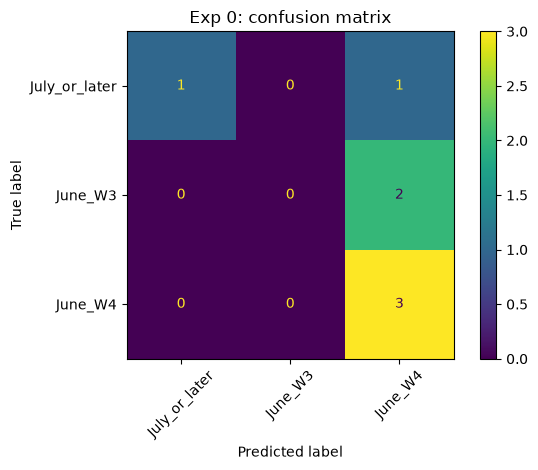

In [5]:
# Experiment 0 (single 80/20 split)
# no stratify=: June_W1 has only 1 year, and stratified splitting would crash
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RS)

rf = RandomForestClassifier(n_estimators=200, random_state=RS).fit(X_tr, y_tr)
base = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)

acc = accuracy_score(y_te, rf.predict(X_te))
base_acc = accuracy_score(y_te, base.predict(X_te))
print(f'Random Forest: {acc:.2f}   Always-guess baseline: {base_acc:.2f}   (test rows: {len(y_te)})')
log('Exp0 annual 80/20 split', acc)
log('Baseline (most frequent)', base_acc)

ConfusionMatrixDisplay.from_estimator(rf, X_te, y_te, xticks_rotation=45)
plt.title('Exp 0: confusion matrix')
plt.tight_layout()
plt.savefig('static/charts/exp0_confusion.png', dpi=150)
plt.show()

c:\Users\Samiksha\Desktop\aiml-cie\venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\Samiksha\Desktop\aiml-cie\venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


per fold: [0.29 0.33 0.17 0.   0.17]
mean 0.19 +/- 0.12   baseline 0.45


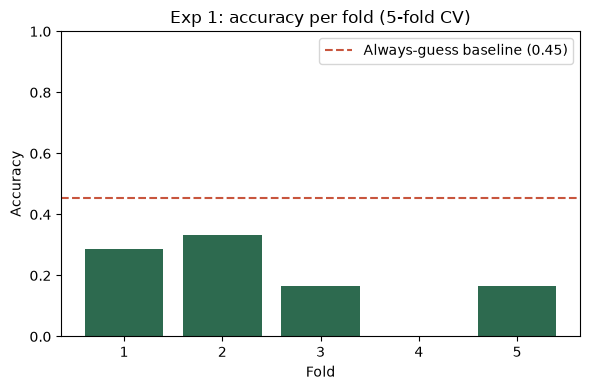

In [6]:
# Experiment 1 (5-fold cross-validation)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
scores = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=RS), X, y, cv=cv, scoring='accuracy')
bscores = cross_val_score(DummyClassifier(strategy='most_frequent'), X, y, cv=cv, scoring='accuracy')
print('per fold:', scores.round(2))
print(f'mean {scores.mean():.2f} +/- {scores.std():.2f}   baseline {bscores.mean():.2f}')
log('Exp1 annual 5-fold', scores.mean(), scores.std())

plt.figure(figsize=(6, 4))
plt.bar(range(1, 6), scores, color='#2D6A4F')
plt.axhline(bscores.mean(), color='#C8553D', linestyle='--', label=f'Always-guess baseline ({bscores.mean():.2f})')
plt.xlabel('Fold'); plt.ylabel('Accuracy'); plt.ylim(0, 1)
plt.title('Exp 1: accuracy per fold (5-fold CV)')
plt.legend(); plt.tight_layout()
plt.savefig('static/charts/exp1_folds.png', dpi=150)
plt.show()

In [ ]:
# temperory
labels = pd.read_csv('data/processed/labels.csv')
print(labels[labels.year.isin([2015, 2025])].to_string(index=False))

 year decision_date  cum_rain  future_rain  longest_dry_days  safe_label
 2015    2015-05-18       6.2         26.8                20           0
 2015    2015-05-25       6.2         77.6                13           0
 2015    2015-06-01       7.7        126.0                 6           0
 2015    2015-06-08      33.0        128.2                 4           0
 2015    2015-06-15      83.8         79.1                11           0
 2015    2015-06-22     133.7         31.0                18           0
 2015    2015-06-29     161.2          6.7                21           0
 2015    2015-07-06     162.9         14.1                15           0
 2015    2015-07-13     164.7         15.0                12           0
 2025    2025-05-18      44.5        224.5                 6           0
 2025    2025-05-25     146.3        174.3                 6           1
 2025    2025-06-01     255.8        118.3                 3           1
 2025    2025-06-08     269.0        123.7         

In [8]:
# temporory
w = pd.read_csv('data/raw/weather_daily.csv', parse_dates=['date']).set_index('date')
print(w.loc['2025-06-24':'2025-07-10', ['precipitation_sum', 'soil_moisture_0_to_7cm']].round(2))

            precipitation_sum  soil_moisture_0_to_7cm
date                                                 
2025-06-24                4.0                    0.46
2025-06-25                3.1                    0.47
2025-06-26                7.2                    0.47
2025-06-27                1.3                    0.47
2025-06-28                0.8                    0.45
2025-06-29                0.4                    0.42
2025-06-30                2.3                    0.42
2025-07-01               11.6                    0.43
2025-07-02                5.7                    0.42
2025-07-03                1.3                    0.43
2025-07-04                2.4                    0.41
2025-07-05                1.5                    0.42
2025-07-06                2.4                    0.45
2025-07-07               13.1                    0.49
2025-07-08                3.2                    0.48
2025-07-09                1.6                    0.48
2025-07-10                0.

In [ ]:
# weekly data, two ways of testing
from sklearn.model_selection import KFold, GroupKFold, cross_validate, cross_val_predict

df = pd.read_csv('data/processed/final_dataset.csv')
FEATURES = ['doy', 'rain_7d', 'rain_14d', 'rain_cum_may1', 'rain_days_14d', 'days_since_rain',
            'tmax_7d', 'tmin_7d', 'soil_7d', 'rh_7d', 'et0_7d', 'oni', 'oni_change', 'dmi', 'soi']
X, y, groups = df[FEATURES], df['safe_label'], df['year']
base_acc = max(y.mean(), 1 - y.mean())          # accuracy of always guessing the common answer
print(X.shape, f'share safe: {y.mean():.3f}   baseline accuracy: {base_acc:.3f}')

rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RS)
scoring = ['accuracy', 'f1']
leaky = cross_validate(rf, X, y, cv=KFold(5, shuffle=True, random_state=RS), scoring=scoring)
honest = cross_validate(rf, X, y, cv=GroupKFold(n_splits=5), groups=groups, scoring=scoring)

for name, r in [('random split (leaky)', leaky), ('grouped by year (honest)', honest)]:
    print(f"{name}: accuracy {r['test_accuracy'].mean():.3f}   F1 {r['test_f1'].mean():.3f}")
    log(f'Exp2 {name} accuracy', r['test_accuracy'].mean(), r['test_accuracy'].std())
    log(f'Exp2 {name} F1', r['test_f1'].mean(), r['test_f1'].std())
log('Baseline weekly (always majority)', base_acc)

(279, 15) share safe: 0.326   baseline accuracy: 0.674
random split (leaky): accuracy 0.867   F1 0.828
grouped by year (honest): accuracy 0.857   F1 0.801


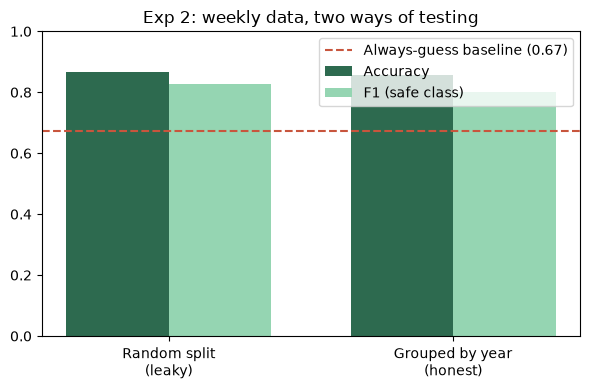

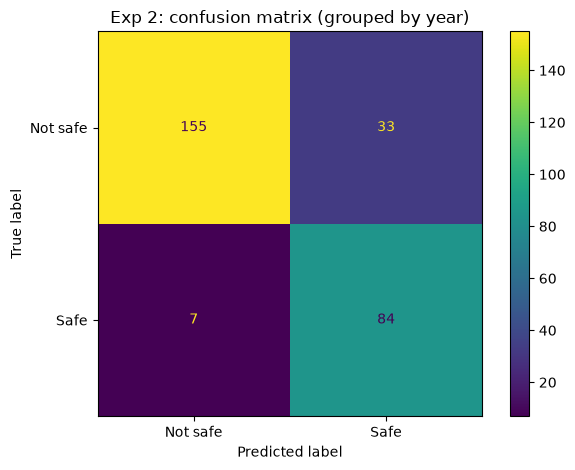

In [10]:
# charts
labels = ['Random split\n(leaky)', 'Grouped by year\n(honest)']
acc = [leaky['test_accuracy'].mean(), honest['test_accuracy'].mean()]
f1 = [leaky['test_f1'].mean(), honest['test_f1'].mean()]
x = np.arange(2)

plt.figure(figsize=(6, 4))
plt.bar(x - 0.18, acc, 0.36, label='Accuracy', color='#2D6A4F')
plt.bar(x + 0.18, f1, 0.36, label='F1 (safe class)', color='#95D5B2')
plt.axhline(base_acc, color='#C8553D', linestyle='--', label=f'Always-guess baseline ({base_acc:.2f})')
plt.xticks(x, labels); plt.ylim(0, 1)
plt.title('Exp 2: weekly data, two ways of testing')
plt.legend(); plt.tight_layout()
plt.savefig('static/charts/exp2_cv.png', dpi=150); plt.show()

pred = cross_val_predict(rf, X, y, cv=GroupKFold(n_splits=5), groups=groups)
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=['Not safe', 'Safe'])
plt.title('Exp 2: confusion matrix (grouped by year)')
plt.tight_layout()
plt.savefig('static/charts/exp2_confusion.png', dpi=150); plt.show()